# RQ3 Analysis: ROUGE Scores

Computes the ROUGE scores (ROUGE-1, ROUGE-2, ROUGE-L) of AI-generated PR descriptions compared to their human-written counterparts.

- Uses the `rouge-score` package.
- ROUGE-1 evaluates unigrams, ROUGE-2 evaluates bigrams, and ROUGE-L evaluates the Longest Common Subsequence.
- Aggregates the Mean and Median for Precision, Recall, and F1-Score for each ROUGE variant.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from rouge_score import rouge_scorer
import os

In [2]:
# Set consistent plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Data Loading & Preparation

In [3]:
csv_path = '../datasets/temperature_1/run_3/detection_results.csv'
df = pd.read_csv(csv_path)

In [4]:
variation_map = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'File Diff',      # Baseline
    'P-4': 'File Contents',
    'P-5': 'Linked Issue',
    'P-6': 'Without File Contents'
}
df['Context_Name'] = df['variation'].map(variation_map)
df['normalized_pr_id'] = df['pr_id'].astype(str)

In [5]:
# FILTERING: Keep only paired PRs
ai_pr_ids = set(df[df['entry_type'] == 'ai']['normalized_pr_id'].unique())
human_pr_ids = set(df[df['entry_type'] == 'human']['normalized_pr_id'].unique())
valid_ids = ai_pr_ids.intersection(human_pr_ids)

In [6]:
# Human subset
human_df = df[(df['entry_type'] == 'human') & (df['normalized_pr_id'].isin(valid_ids))].copy()
human_df['model'] = 'Human'

# Prepare a mapping from pr_id to human_text for reference matching
human_text_map = human_df.set_index('normalized_pr_id')['text'].to_dict()

In [7]:
# AI subset
ai_df = df[(df['entry_type'] == 'ai') & (df['normalized_pr_id'].isin(valid_ids))].copy()

# Add the corresponding human reference text to each AI entry
ai_df['reference_text'] = ai_df['normalized_pr_id'].map(human_text_map)

In [8]:
print(f"Paired PR Count: {len(valid_ids)}")
print(f"Models found: {ai_df['model'].unique()}")
print(f"Human entries: {len(human_df)}, AI entries: {len(ai_df)}")

Paired PR Count: 308
Models found: <StringArray>
['meta-llama/llama-3.1-70b-instruct',             'gpt-5-mini-2025-08-07',
         'Qwen/Qwen2.5-72B-Instruct']
Length: 3, dtype: str
Human entries: 308, AI entries: 5528


## 2. Compute ROUGE Scores

In [9]:
scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)

def compute_rouge(row):
    ref = str(row['reference_text']) if not pd.isna(row['reference_text']) else ""
    cand = str(row['text']) if not pd.isna(row['text']) else ""
    
    if not ref.strip() or not cand.strip():
        return pd.Series({
            'rouge1_precision': np.nan, 'rouge1_recall': np.nan, 'rouge1_fmeasure': np.nan,
            'rouge2_precision': np.nan, 'rouge2_recall': np.nan, 'rouge2_fmeasure': np.nan,
            'rougeL_precision': np.nan, 'rougeL_recall': np.nan, 'rougeL_fmeasure': np.nan,
        })
    
    scores = scorer.score(ref, cand)
    
    return pd.Series({
        'rouge1_precision': scores['rouge1'].precision,
        'rouge1_recall': scores['rouge1'].recall,
        'rouge1_fmeasure': scores['rouge1'].fmeasure,
        'rouge2_precision': scores['rouge2'].precision,
        'rouge2_recall': scores['rouge2'].recall,
        'rouge2_fmeasure': scores['rouge2'].fmeasure,
        'rougeL_precision': scores['rougeL'].precision,
        'rougeL_recall': scores['rougeL'].recall,
        'rougeL_fmeasure': scores['rougeL'].fmeasure,
    })

In [10]:
# We only calculate ROUGE for the AI subset since they are compared against the human reference
print("Computing ROUGE metrics...")
rouge_cols = [
    'rouge1_precision', 'rouge1_recall', 'rouge1_fmeasure',
    'rouge2_precision', 'rouge2_recall', 'rouge2_fmeasure',
    'rougeL_precision', 'rougeL_recall', 'rougeL_fmeasure'
]
ai_df[rouge_cols] = ai_df.apply(compute_rouge, axis=1)

Computing ROUGE metrics...


In [11]:
# Filter out rows where calculation failed (due to empty strings)
ai_df = ai_df.dropna(subset=rouge_cols)

print("ROUGE metrics computed.")
print(f"AI dataset size with computed metrics: {len(ai_df)}")
display(ai_df[['entry_type', 'model', 'rouge1_fmeasure', 'rouge2_fmeasure', 'rougeL_fmeasure']].head(10))

ROUGE metrics computed.
AI dataset size with computed metrics: 5528


,entry_type,model,rouge1_fmeasure,rouge2_fmeasure,rougeL_fmeasure
0,ai,meta-llama/llama-3.1-70b-instruct,0.296296,0.200000,0.259259
1,ai,gpt-5-mini-2025-08-07,0.199566,0.013072,0.117137
2,ai,gpt-5-mini-2025-08-07,0.208955,0.018018,0.095522
3,ai,gpt-5-mini-2025-08-07,0.550790,0.344671,0.406321
4,ai,Qwen/Qwen2.5-72B-Instruct,0.196721,0.000000,0.131148
5,ai,meta-llama/llama-3.1-70b-instruct,0.074627,0.015152,0.059701
6,ai,meta-llama/llama-3.1-70b-instruct,0.222222,0.112903,0.126984
7,ai,gpt-5-mini-2025-08-07,0.256983,0.052336,0.126629
8,ai,Qwen/Qwen2.5-72B-Instruct,0.305344,0.108527,0.229008
9,ai,Qwen/Qwen2.5-72B-Instruct,0.181818,0.018519,0.109091


## 3. ROUGE-L Boxplots by Context per LLM

This mirrors the plotting design used in other RQ3 notebooks:

- One panel per LLM model (stacked vertically).
- Each panel includes the 6 AI context boxplots.
- No Human boxplot is included in this view.

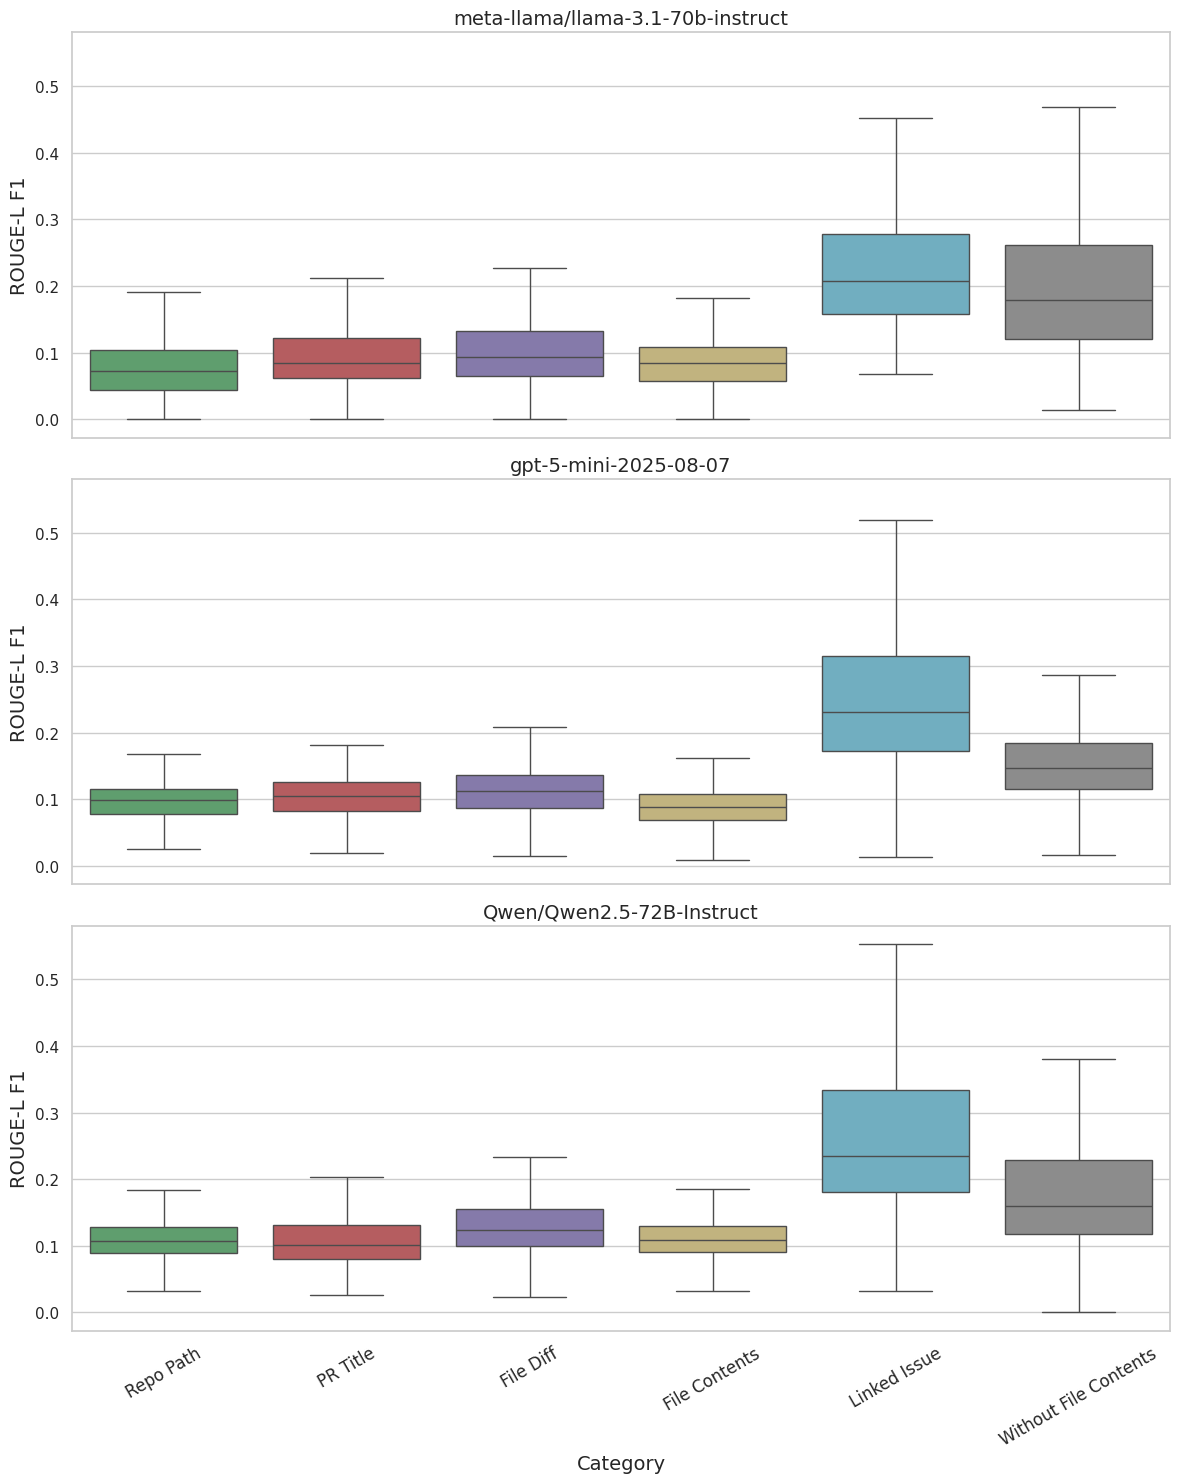

In [12]:
context_order = ['Repo Path', 'PR Title', 'File Diff', 'File Contents', 'Linked Issue', 'Without File Contents']
llm_models = ai_df['model'].dropna().unique().tolist()
x_order = context_order
palette_map = {
    'Repo Path': '#55A868',
    'PR Title': '#C44E52',
    'File Diff': '#8172B2',
    'File Contents': '#CCB974',
    'Linked Issue': '#64B5CD',
    'Without File Contents': '#8C8C8C'
}

fig, axes = plt.subplots(len(llm_models), 1, figsize=(12, 5 * len(llm_models)), sharex=True, sharey=True)
if len(llm_models) == 1:
    axes = [axes]

for i, model in enumerate(llm_models):
    ax = axes[i]
    ax.set_title(model, fontsize=16)

    panel_df = ai_df[ai_df['model'] == model][['rougeL_fmeasure', 'Context_Name']].dropna().copy()
    panel_df['Category'] = panel_df['Context_Name']

    sns.boxplot(
        data=panel_df,
        x='Category',
        y='rougeL_fmeasure',
        order=x_order,
        hue='Category',
        hue_order=x_order,
        ax=ax,
        palette=palette_map,
        dodge=False,
        legend=False,
        showfliers=False
    )

    ax.set_xlabel('Category' if i == len(llm_models) - 1 else '', fontsize=16)
    ax.set_ylabel('ROUGE-L F1', fontsize=16)
    ax.tick_params(axis='x', rotation=30, labelsize=16)
    ax.tick_params(axis='y', labelsize=16)

plt.tight_layout()
from pathlib import Path
Path('outputs/figures_pdf').mkdir(parents=True, exist_ok=True)
plt.savefig(str(Path('outputs/figures_pdf') / 'rouge.pdf'), bbox_inches='tight', dpi=150)
plt.show()

## 3. Final RQ3 Answer: Human Baseline Comparison (ROUGE)

This section directly answers the core RQ3 objective using paired AI↔Human ROUGE results.

- **Reference**: Original human-written PR descriptions (`n=308`, paired PR set).
- **Candidates**: AI descriptions for each model and context (P-1 ... P-6).
- **Reported**: Mean/Median ROUGE F1 per [Model, Context], Cliff's δ vs Human Baseline (ROUGE-L), and ranking by highest ROUGE-L Median F1.

In [13]:
# Local helpers (self-contained final section)
def cliffs_delta(lst1, lst2):
    m, n = len(lst1), len(lst2)
    if m == 0 or n == 0:
        return 0.0
    dom = 0
    for x in lst1:
        for y in lst2:
            if x > y:
                dom += 1
            elif x < y:
                dom -= 1
    return dom / (m * n)

def interpret_cliffs_delta(d):
    d = abs(d)
    if d < 0.147:
        return "Negligible"
    elif d < 0.33:
        return "Small"
    elif d < 0.474:
        return "Medium"
    else:
        return "Large"

variation_names = ['Repo Path', 'PR Title', 'File Diff', 'File Contents', 'Linked Issue', 'Without File Contents']

# Human baseline (self-vs-self ROUGE)
human_baseline_df = human_df[['normalized_pr_id', 'text']].copy()
human_baseline_df['text'] = human_baseline_df['text'].fillna('').astype(str)
human_baseline_df = human_baseline_df.sort_values('normalized_pr_id').drop_duplicates('normalized_pr_id')

def compute_rouge_pair(ref_text: str, cand_text: str) -> dict:
    ref = '' if pd.isna(ref_text) else str(ref_text)
    cand = '' if pd.isna(cand_text) else str(cand_text)
    if not ref.strip() or not cand.strip():
        return {'rouge1_f': np.nan, 'rouge2_f': np.nan, 'rougeL_f': np.nan}
    s = scorer.score(ref, cand)
    return {
        'rouge1_f': s['rouge1'].fmeasure,
        'rouge2_f': s['rouge2'].fmeasure,
        'rougeL_f': s['rougeL'].fmeasure
    }

human_r1 = []
human_r2 = []
human_rl = []
for txt in human_baseline_df['text'].tolist():
    r = compute_rouge_pair(txt, txt)
    human_r1.append(r['rouge1_f'])
    human_r2.append(r['rouge2_f'])
    human_rl.append(r['rougeL_f'])

human_baseline_df['human_rouge1_f'] = human_r1
human_baseline_df['human_rouge2_f'] = human_r2
human_baseline_df['human_rougeL_f'] = human_rl

human_rougeL_vals = human_baseline_df['human_rougeL_f'].dropna().values
print(f"Human baseline n = {len(human_rougeL_vals)}")
print(f"Human ROUGE-L mean F1 = {np.mean(human_rougeL_vals):.4f}")
print(f"Human ROUGE-L median F1 = {np.median(human_rougeL_vals):.4f}")

# Compare each [Model, Context] against human baseline
rows = []
for model in sorted(ai_df['model'].unique()):
    for ctx in variation_names:
        subset = ai_df[(ai_df['model'] == model) & (ai_df['Context_Name'] == ctx)]
        if subset.empty:
            continue

        r1 = subset['rouge1_fmeasure'].dropna().values
        r2 = subset['rouge2_fmeasure'].dropna().values
        rl = subset['rougeL_fmeasure'].dropna().values
        if len(rl) == 0:
            continue

        delta_rl = cliffs_delta(rl.tolist(), human_rougeL_vals.tolist())
        rows.append({
            'Model': model,
            'Context': ctx,
            'N_AI': len(rl),
            'N_Human': len(human_rougeL_vals),
            'ROUGE-1 Mean F1': round(float(np.mean(r1)), 4),
            'ROUGE-1 Median F1': round(float(np.median(r1)), 4),
            'ROUGE-2 Mean F1': round(float(np.mean(r2)), 4),
            'ROUGE-2 Median F1': round(float(np.median(r2)), 4),
            'ROUGE-L Mean F1': round(float(np.mean(rl)), 4),
            'ROUGE-L Median F1': round(float(np.median(rl)), 4),
            "Cliff's Delta (ROUGE-L AI vs Human)": round(float(delta_rl), 4),
            'Effect Size': interpret_cliffs_delta(delta_rl)
        })

rouge_cmp_df = pd.DataFrame(rows)
rouge_cmp_df = rouge_cmp_df.sort_values(['Model', 'ROUGE-L Median F1', 'ROUGE-L Mean F1'], ascending=[True, False, False])
rouge_cmp_df['Most Human Rank (within model)'] = rouge_cmp_df.groupby('Model')['ROUGE-L Median F1'].rank(method='dense', ascending=False).astype(int)

print('\n[Model, Context] vs Human baseline (sorted by highest ROUGE-L Median F1):')
display(rouge_cmp_df)

best_context_per_model_df = (
    rouge_cmp_df.sort_values(['Model', 'ROUGE-L Median F1', 'ROUGE-L Mean F1'], ascending=[True, False, False])
    .groupby('Model', as_index=False)
    .first()[['Model', 'Context', 'ROUGE-L Mean F1', 'ROUGE-L Median F1', "Cliff's Delta (ROUGE-L AI vs Human)", 'Effect Size', 'Most Human Rank (within model)']]
    .sort_values('Model')
)

print('\nBest context per model (highest ROUGE-L Median F1):')
display(best_context_per_model_df)

os.makedirs('outputs', exist_ok=True)
rouge_cmp_df.to_csv('outputs/rq3_rouge_ai_vs_human_baseline.csv', index=False)
best_context_per_model_df.to_csv('outputs/rq3_rouge_most_human_context_per_model.csv', index=False)
print('Saved: outputs/rq3_rouge_ai_vs_human_baseline.csv')
print('Saved: outputs/rq3_rouge_most_human_context_per_model.csv')

Human baseline n = 308
Human ROUGE-L mean F1 = 1.0000
Human ROUGE-L median F1 = 1.0000

[Model, Context] vs Human baseline (sorted by highest ROUGE-L Median F1):


,Model,Context,N_AI,N_Human,ROUGE-1 Mean F1,ROUGE-1 Median F1,ROUGE-2 Mean F1,ROUGE-2 Median F1,ROUGE-L Mean F1,ROUGE-L Median F1,Cliff's Delta (ROUGE-L AI vs Human),Effect Size,Most Human Rank (within model)
4,Qwen/Qwen2.5-72B-Instruct,Linked Issue,308,308,0.3925,0.3771,0.1497,0.1235,0.2662,0.2347,-1.0,Large,1
5,Qwen/Qwen2.5-72B-Instruct,Without File Contents,308,308,0.3103,0.2989,0.1048,0.0732,0.1891,0.1600,-1.0,Large,2
2,Qwen/Qwen2.5-72B-Instruct,File Diff,308,308,0.2271,0.2313,0.0422,0.0331,0.1288,0.1241,-1.0,Large,3
3,Qwen/Qwen2.5-72B-Instruct,File Contents,302,308,0.1973,0.2058,0.0229,0.0207,0.1076,0.1086,-1.0,Large,4
0,Qwen/Qwen2.5-72B-Instruct,Repo Path,308,308,0.1848,0.1866,0.0241,0.0247,0.1067,0.1066,-1.0,Large,5
1,Qwen/Qwen2.5-72B-Instruct,PR Title,308,308,0.1750,0.1747,0.0309,0.0267,0.1082,0.1009,-1.0,Large,6
10,gpt-5-mini-2025-08-07,Linked Issue,308,308,0.3825,0.3871,0.1548,0.1351,0.2485,0.2315,-1.0,Large,1
11,gpt-5-mini-2025-08-07,Without File Contents,308,308,0.2812,0.2883,0.0734,0.0633,0.1508,0.1471,-1.0,Large,2
8,gpt-5-mini-2025-08-07,File Diff,308,308,0.2105,0.2194,0.0286,0.0221,0.1117,0.1127,-1.0,Large,3
7,gpt-5-mini-2025-08-07,PR Title,308,308,0.1939,0.2060,0.0218,0.0170,0.1032,0.1051,-1.0,Large,4



Best context per model (highest ROUGE-L Median F1):


,Model,Context,ROUGE-L Mean F1,ROUGE-L Median F1,Cliff's Delta (ROUGE-L AI vs Human),Effect Size,Most Human Rank (within model)
0,Qwen/Qwen2.5-72B-Instruct,Linked Issue,0.2662,0.2347,-1.0,Large,1
1,gpt-5-mini-2025-08-07,Linked Issue,0.2485,0.2315,-1.0,Large,1
2,meta-llama/llama-3.1-70b-instruct,Linked Issue,0.2359,0.2068,-1.0,Large,1


Saved: outputs/rq3_rouge_ai_vs_human_baseline.csv
Saved: outputs/rq3_rouge_most_human_context_per_model.csv
